### This notebook estimates the distribution of financial losses conditional on a successful third-party credential compromise affecting NovaFlow.
We will be able to estimate:
- Expected financial loss per successful incident.
- The distribution of incident losses, including extreme outcomes.
- Contributions from primary response, secondary response, fines and judgments, and reputation.
- How technical severity influences financial consequences.

NOTE: These are conditional incident losses, not annual cyber risk estimates. This notebook doesn't incorporate how often successful incidents occur.

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
project_root = cwd if (cwd / "config").exists() else cwd.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.incident_simulation import (
    simulate_incidents,
    summarize_incident_losses,
)

df = simulate_incidents(
    n_incidents=50_000,
    seed=42,
    include_details=True,
)

print(f"Simulated incidents: {len(df):,}")
display(df.head())

Simulated incidents: 50,000


,incident_id,technical_severity,affected_customers,primary_loss_usd,secondary_response_planning_loss_usd,secondary_fines_judgement_loss_usd,secondary_reputation_loss_usd,total_incident_loss_usd,indicator_public_visibility,indicator_notification,...,reputation_unaffected_churn_probability,reputation_lost_deal_probability,reputation_affected_churn_count,reputation_unaffected_churn_count,reputation_total_churn_count,reputation_otherwise_won_opportunities,reputation_lost_deals_count,reputation_affected_churn_loss_usd,reputation_unaffected_churn_loss_usd,reputation_lost_deals_loss_usd
0,1,0.304717,1991,133479.283667,226464.091057,0.000000,630000,9.899434e+05,False,True,...,0.000170,0.006154,3,0,3,40,0,630000,0,0
1,2,-1.039984,590,113686.342822,130930.088512,0.000000,210000,4.546164e+05,False,True,...,0.000119,0.003577,0,1,1,37,0,0,210000,0
2,3,0.750451,1687,167981.192551,87902.880399,0.000000,630000,8.858841e+05,False,True,...,0.000191,0.007365,2,0,2,40,1,420000,0,210000
3,4,0.940565,1364,137591.639906,530342.814426,655640.740439,1260000,2.583575e+06,False,True,...,0.000201,0.007950,5,0,5,38,1,1050000,0,210000
4,5,-1.951035,2161,99861.064075,111160.982422,0.000000,210000,4.210220e+05,False,True,...,0.000094,0.002475,1,0,1,38,0,210000,0,0


In [3]:
summary = summarize_incident_losses(df)

formatted = summary.copy()

for col in formatted.columns:
    if col.endswith("_usd"):
        formatted[col] = formatted[col].map(
            lambda x: f"${x:,.0f}"
        )

display(formatted)

,component,mean_usd,median_usd,p90_usd,p95_usd,p99_usd,maximum_usd
0,primary_loss_usd,"$146,899","$142,853","$217,444","$237,473","$271,249","$339,772"
1,secondary_response_planning_loss_usd,"$187,372","$154,175","$319,585","$428,196","$790,293","$2,754,973"
2,secondary_fines_judgement_loss_usd,"$111,431",$0,$0,"$748,960","$2,422,139","$30,194,929"
3,secondary_reputation_loss_usd,"$788,012","$630,000","$1,680,000","$2,310,000","$3,570,000","$11,130,000"
4,total_incident_loss_usd,"$1,233,714","$913,853","$2,522,619","$3,340,284","$5,461,741","$31,379,901"


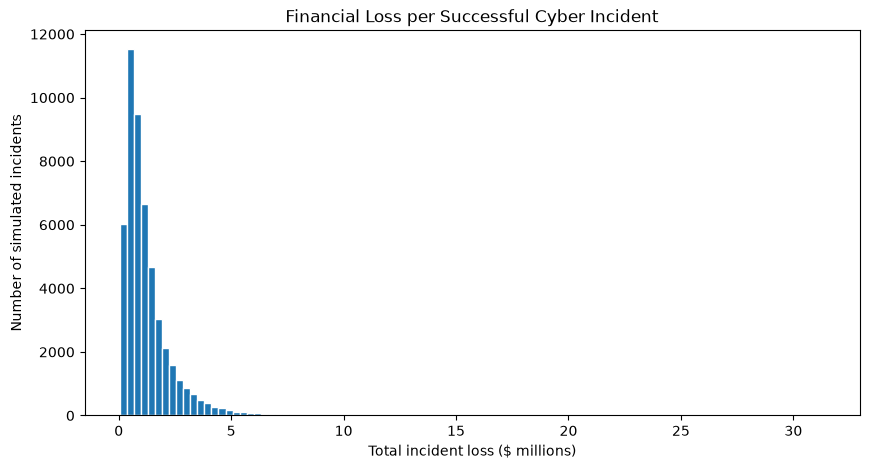

In [ ]:
loss_millions = df["total_incident_loss_usd"] / 1_000_000

plt.figure(figsize=(10, 5))

plt.hist(
    loss_millions,
    bins=100,
    edgecolor="white",
)

plt.xlabel("Total incident loss ($ millions)")
plt.ylabel("Number of simulated incidents")
plt.title("Financial Loss per Successful Cyber Incident")

plt.show()

#Because fines and judgments follow Lognormal distributions, the total loss distribution will likely be right-skewed.

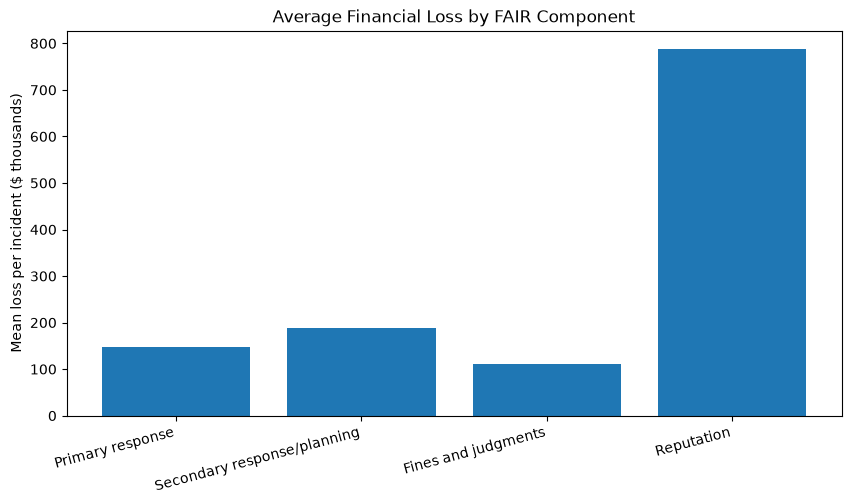

In [5]:
loss_columns = [
    "primary_loss_usd",
    "secondary_response_planning_loss_usd",
    "secondary_fines_judgement_loss_usd",
    "secondary_reputation_loss_usd",
]

labels = [
    "Primary response",
    "Secondary response/planning",
    "Fines and judgments",
    "Reputation",
]

mean_losses = df[loss_columns].mean() / 1000

plt.figure(figsize=(10, 5))

plt.bar(labels, mean_losses)

plt.ylabel("Mean loss per incident ($ thousands)")
plt.title("Average Financial Loss by FAIR Component")
plt.xticks(rotation=15, ha="right")

plt.show()

In [ ]:
df["severity_group"] = pd.qcut(
    df["technical_severity"],
    q=5,
    labels=[
        "Very low",
        "Low",
        "Moderate",
        "High",
        "Very high",
    ],
)

severity_summary = (
    df.groupby("severity_group", observed=True)[
        "total_incident_loss_usd"
    ]
    .agg(["mean", "median", "count"])
)

display(severity_summary)

#Understand how the shared severity factor influences the financial consequences of successful incidents.

,mean,median,count
severity_group,,,
Very low,4.942863e+05,4.176951e+05,10000
Low,7.676172e+05,6.685716e+05,10000
Moderate,1.038115e+06,9.057135e+05,10000
High,1.424182e+06,1.237962e+06,10000
Very high,2.444370e+06,2.114217e+06,10000
